# Student Performance Analysis – Sample Data Analyst Project
*Audience:* B.Tech 1st Year students (Data Analyst track) | *Tools:* Python, pandas, matplotlib, seaborn

# Bank customer Analysis

## 1. Business Problem

 The retail banking team of a mid-sized Indian bank wants to know why some customers keep large balances while others keep very little. Customers with low balances are less profitable and more likely to leave. Your analysis should tell the team which customer traits go with higher balances and which customers need attention first.

### Questions to Answer

1. What does Avg_Monthly_Balance look like overall?

2. Do Monthly_Income and Tenure_Years affect Avg_Monthly_Balance?

3. Does Avg_Monthly_Balance differ by Account_Type, City, Employment_Type and Preferred_Channel?

4.  Which customers need attention? Label a customer “At Risk” if Avg_Monthly_Balance is below ₹40,000. How many are there, and what do they have in common?

> The dataset is **synthetic** (computer-generated) and contains no real Market data.

## 2. Import libraries

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [29]:
df = pd.read_csv('../data/raw/BANK customer.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 12)


,Customer_ID,City,Account_Type,Employment_Type,Mobile_Banking_User,Age,Monthly_Income,Tenure_Years,Monthly_Transactions,Credit_Score,Last_Transaction_Date,Avg_Monthly_Balance
0,C1175,Bengaluru,Salary,Self-Employed,Yes,56,53500.0,11.7,18,615.0,2026-01-24,59260
1,C1222,Mumbai,Savings,Retired,Yes,212,39500.0,6.6,27,724.0,2025-11-12,174890
2,C1164,Delhi,Salary,Salaried,Yes,47,33500.0,15.1,14,680.0,2025-01-10,68070
3,C1149,Mumbai,Savings,Retired,Yes,64,23500.0,6.8,19,681.0,2025-02-18,5850
4,C1238,Delhi,Savings,Self-Employed,Yes,26,62500.0,8.0,30,654.0,2026-01-07,76860


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            255 non-null    str    
 1   City                   255 non-null    str    
 2   Account_Type           255 non-null    str    
 3   Employment_Type        251 non-null    str    
 4   Mobile_Banking_User    255 non-null    str    
 5   Age                    255 non-null    int64  
 6   Monthly_Income         250 non-null    float64
 7   Tenure_Years           250 non-null    float64
 8   Monthly_Transactions   255 non-null    int64  
 9   Credit_Score           249 non-null    float64
 10  Last_Transaction_Date  255 non-null    str    
 11  Avg_Monthly_Balance    255 non-null    int64  
dtypes: float64(3), int64(3), str(6)
memory usage: 24.0 KB


In [31]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Employment_Type    4
Monthly_Income     5
Tenure_Years       5
Credit_Score       6
dtype: int64

Duplicate rows: 5


,Age,Monthly_Income,Tenure_Years,Monthly_Transactions,Credit_Score,Avg_Monthly_Balance
count,255.0,250.0,250.0,255.0,249.0,255.0
mean,42.0,39414.0,6.9,27.3,707.1,77082.9
std,20.1,26211.4,4.8,11.8,66.3,52687.4
min,-27.0,5000.0,0.5,3.0,511.0,500.0
25%,24.0,19125.0,3.1,18.0,663.0,33770.0
50%,42.0,36000.0,5.6,27.0,703.0,73480.0
75%,54.0,51500.0,10.2,35.0,757.0,118270.0
max,212.0,151000.0,17.9,60.0,893.0,212530.0


**What we found:** some missing values, duplicate rows, inconsistent text in `Gender` (e.g. `male`, `FEMALE`) and an impossible attendance value above 100. We clean these next.

## 4. Clean the data

In [ ]:


clean = df.copy()

#1, we delete duplicate rows:
clean = clean.drop_duplicates()

#2, we standardise the inconsistent values in city field:
clean['City'] = clean['City'].str.strip().str.title()

#3, we fix impossible values by replacing it with null temperarily:
clean.loc[clean['monthly_income']<0, 'monthly_income'] = np.nan

#4, we fill null vallues in number fields with median of their field:
int_col = ["monthly_income", "employment_type", "moblie_banking_user", "tenure_year", "credit_score"]
for col in int_col:
    clean[col] = clean[col].fillna(clean[col].median())

#4.5, filling the Genre field with Unknown to preserve the data accuracy:
clean['Genre'] = clean['Genre'].fillna("Unknown")

#5, rearrage the rows and sort by Game_ID:
clean = clean.sort_values(by='bank_account').reset_index(drop=True)

print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

## 5. Create new columns (feature engineering)


In [35]:
df["Age_Group"] = pd.cut(df["Age"], bins=[0, 25, 40, 60, 100],
                         labels=["Young", "Adult", "Middle_Aged", "Senior"])

df["Income_Category"] = pd.cut(df["Monthly_Income"], bins=[0, 25000, 50000, 100000, float("inf")],
                              labels=["Low", "Medium", "High", "Very_High"])

df["Tenure_Category"] = pd.cut(df["Tenure_Years"], bins=[-1, 2, 5, 10, float("inf")],
                               labels=["New", "Short_Term", "Medium_Term", "Long_Term"])

print(df.head())

  Customer_ID       City Account_Type Employment_Type Mobile_Banking_User  \
0       C1175  Bengaluru       Salary   Self-Employed                 Yes   
1       C1222     Mumbai      Savings         Retired                 Yes   
2       C1164      Delhi       Salary        Salaried                 Yes   
3       C1149     Mumbai      Savings         Retired                 Yes   
4       C1238      Delhi      Savings   Self-Employed                 Yes   

   Age  Monthly_Income  Tenure_Years  Monthly_Transactions  Credit_Score  \
0   56         53500.0          11.7                    18         615.0   
1  212         39500.0           6.6                    27         724.0   
2   47         33500.0          15.1                    14         680.0   
3   64         23500.0           6.8                    19         681.0   
4   26         62500.0           8.0                    30         654.0   

  Last_Transaction_Date  Avg_Monthly_Balance    Age_Group Income_Category  \
0  

## 6. Exploratory data analysis (EDA)

Q1. What does Avg_Monthly_Balance look like overall?

count       250.000000
mean      77033.720000
std       52668.481069
min         500.000000
25%       33850.000000
50%       73130.000000
75%      118600.000000
max      212530.000000
Name: Avg_Monthly_Balance, dtype: float64
Mean: 77033.72
Median: 73130.0


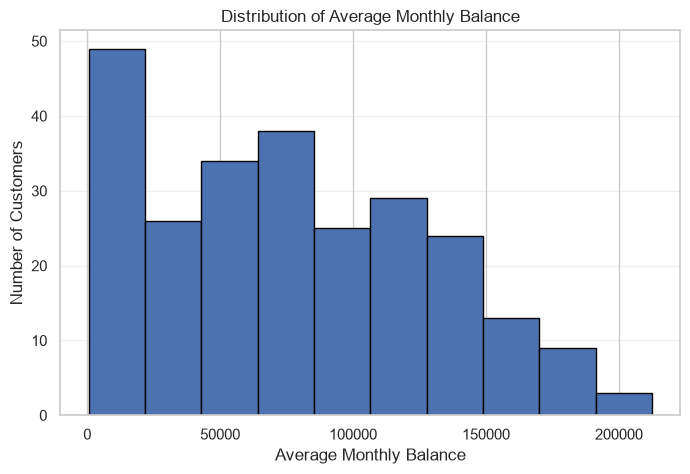

In [38]:
# Overall summary of Avg_Monthly_Balance
print(clean['Avg_Monthly_Balance'].describe())

# Mean and median
print("Mean:", clean['Avg_Monthly_Balance'].mean())
print("Median:", clean['Avg_Monthly_Balance'].median())

# Plot distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(clean['Avg_Monthly_Balance'], bins=10, edgecolor='black')

plt.title('Distribution of Average Monthly Balance')
plt.xlabel('Average Monthly Balance')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.show()

Q2 Do Monthly_Income and Tenure_Years affect Avg_Monthly_Balance

Income vs Balance Correlation: 0.49030470472522064
Tenure vs Balance Correlation: 0.47006616195965073


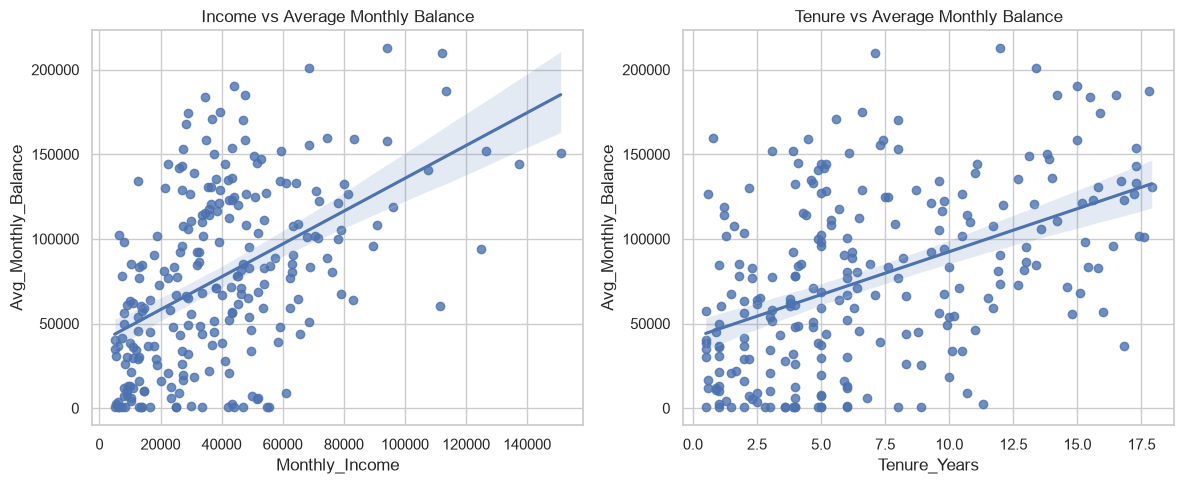

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation
print("Income vs Balance Correlation:",
      clean['Monthly_Income'].corr(clean['Avg_Monthly_Balance']))

print("Tenure vs Balance Correlation:",
      clean['Tenure_Years'].corr(clean['Avg_Monthly_Balance']))

# Visualize relationship
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(x='Monthly_Income', y='Avg_Monthly_Balance',
            data=clean, ax=axes[0])
axes[0].set_title('Income vs Average Monthly Balance')

sns.regplot(x='Tenure_Years', y='Avg_Monthly_Balance',
            data=clean, ax=axes[1])
axes[1].set_title('Tenure vs Average Monthly Balance')

plt.tight_layout()
plt.show()

Q3Does Avg_Monthly_Balance differ by Account_Type, City, Employment_Type and Preferred_Channel?

In [ ]:
# Average balance by Account Type
clean.groupby('Account_Type')['Avg_Monthly_Balance'].mean().sort_values(ascending=False)

# Average balance by City
clean.groupby('City')['Avg_Monthly_Balance'].mean().sort_values(ascending=False)

# Average balance by Employment Type
clean.groupby('Employment_Type')['Avg_Monthly_Balance'].mean().sort_values(ascending=False)

# Average balance by Preferred Channel
clean.groupby('Preferred_Channel')['Avg_Monthly_Balance'].mean().sort_values(ascending=False)

In [43]:
print("Account Type:\n", account)
print("\nCity:\n", city)
print("\nEmployment Type:\n", employment)


Account Type:
 Account_Type
Current    109851.388889
Salary      72742.500000
Savings     70889.577465
Name: Avg_Monthly_Balance, dtype: float64

City:
 City
Bengaluru    80551.886792
Delhi        77149.285714
Kolkata      74688.695652
Lucknow      76424.285714
Mumbai       75014.838710
Name: Avg_Monthly_Balance, dtype: float64

Employment Type:
 Employment_Type
Retired          75879.142857
Salaried         89945.604396
Self-Employed    93365.428571
Student          32108.200000
Name: Avg_Monthly_Balance, dtype: float64


Q4 Which customers need attention? Label a customer “At Risk” if Avg_Monthly_Balance is below ₹40,000. How many are there, and what do they have in common?

In [46]:
clean['Customer_Status'] = clean['Avg_Monthly_Balance'].apply(
    lambda x: 'At Risk' if x < 40000 else 'Healthy'
)

clean[['Customer_ID', 'Avg_Monthly_Balance', 'Customer_Status']].head()

,Customer_ID,Avg_Monthly_Balance,Customer_Status
0,C1175,59260,Healthy
1,C1222,174890,Healthy
2,C1164,68070,Healthy
3,C1149,5850,At Risk
4,C1238,76860,Healthy


COUNT AT RISK CUSTOMER

In [47]:
risk_count = (clean['Customer_Status'] == 'At Risk').sum()

print("Total At Risk Customers:", risk_count)

Total At Risk Customers: 73


Find what At Risk customers have in common

In [49]:
risk = clean[clean['Customer_Status'] == 'At Risk']

print("At Risk customers by Account Type:")
print(risk['Account_Type'].value_counts())

print("\nAt Risk customers by City:")
print(risk['City'].value_counts())

print("\nAt Risk customers by Employment Type:")
print(risk['Employment_Type'].value_counts())

print("\nAt Risk customers by Preferred Channel:")

print("\nAverage Income of At Risk Customers:", risk['Monthly_Income'].mean())
print("Average Tenure of At Risk Customers:", risk['Tenure_Years'].mean())

At Risk customers by Account Type:
Account_Type
Savings    43
Salary     24
Current     6
Name: count, dtype: int64

At Risk customers by City:
City
Delhi        22
Mumbai       20
Bengaluru    17
Lucknow       9
Kolkata       5
Name: count, dtype: int64

At Risk customers by Employment Type:
Employment_Type
Student          33
Salaried         15
Self-Employed    14
Retired          10
Name: count, dtype: int64

At Risk customers by Preferred Channel:

Average Income of At Risk Customers: 22802.816901408452
Average Tenure of At Risk Customers: 4.090140845070422


## 7. Key insights (generated from the data)

This code will identify:
- Average monthly balance overall
- Highest-balance account type, city, employment type, and channel
- Relationship between income, tenure, and balance
- Number and percentage of At Risk customers
- Common characteristics of At Risk customers

In [51]:
overall_avg = clean['Avg_Monthly_Balance'].mean()
print(f"Overall Average Monthly Balance: ₹{overall_avg:,.2f}")


Overall Average Monthly Balance: ₹77,033.72


In [52]:
# 2. Account Type with highest average balance
account_avg = clean.groupby('Account_Type')['Avg_Monthly_Balance'].mean()
best_account = account_avg.idxmax()

print(f"Highest Balance Account Type: {best_account} (₹{account_avg.max():,.2f})")


Highest Balance Account Type: Current (₹109,851.39)


In [57]:
 #Relationship between Income and Balance
income_corr = clean['Monthly_Income'].corr(clean['Avg_Monthly_Balance'])
print(f"Income-Balance Correlation: {income_corr:.2f}")



Income-Balance Correlation: 0.49


In [58]:
#Relationship between Tenure and Balance
tenure_corr = clean['Tenure_Years'].corr(clean['Avg_Monthly_Balance'])
print(f"Tenure-Balance Correlation: {tenure_corr:.2f}")



Tenure-Balance Correlation: 0.47


In [59]:
#At Risk Customers (Balance below ₹40,000)
clean['Customer_Status'] = clean['Avg_Monthly_Balance'].apply(
    lambda x: 'At Risk' if x < 40000 else 'Healthy'
)

risk = clean[clean['Customer_Status'] == 'At Risk']

risk_count = len(risk)
risk_pct = (risk_count / len(clean)) * 100

print(f"\nAt Risk Customers: {risk_count}")
print(f"At Risk Percentage: {risk_pct:.2f}%")


At Risk Customers: 73
At Risk Percentage: 29.20%


In [61]:
#Common characteristics of At Risk customers
if risk_count > 0:
    print("\nCommon Characteristics of At Risk Customers:")

    print("Most Common Account Type:",
          risk['Account_Type'].mode()[0])

    print("Most Common City:",
          risk['City'].mode()[0])

    print("Most Common Employment Type:",
          risk['Employment_Type'].mode()[0])


    print(f"Average Income of At Risk Customers: ₹{risk['Monthly_Income'].mean():,.2f}")

    print(f"Average Tenure of At Risk Customers: {risk['Tenure_Years'].mean():.1f} years")




Common Characteristics of At Risk Customers:
Most Common Account Type: Savings
Most Common City: Delhi
Most Common Employment Type: Student
Average Income of At Risk Customers: ₹22,802.82
Average Tenure of At Risk Customers: 4.1 years


In [63]:
#  Final Summary
print("\n--- KEY INSIGHTS SUMMARY ---")
print(f"Average customer balance is ₹{overall_avg:,.2f}.")
print(f"{best_account} account holders have the highest average balance.")
print(f"{best_city} has the highest average customer balance.")
print(f"{risk_count} customers ({risk_pct:.2f}%) are At Risk.")


--- KEY INSIGHTS SUMMARY ---
Average customer balance is ₹77,033.72.
Current account holders have the highest average balance.
Bengaluru has the highest average customer balance.
73 customers (29.20%) are At Risk.


## 8. Recommendations

In [65]:
print("BANK CUSTOMER RECOMMENDATIONS\n")

# At Risk customers
if risk_count > 0:
    print(f"1. Customer Retention: Focus on the {risk_count} At Risk customers ")
    print("   with balances below ₹40,000 through personalized offers and support.\n")

#Account Type
print(f"2. Account Strategy: Study {best_account} account holders to understand")
print("   their balance patterns and design suitable products for other customers.\n")

# City
print(f"3. City Strategy: Focus on {best_city} to understand customer saving habits")
print("   and use successful strategies in other cities.\n")



# Income and Balance relationship
if income_corr > 0.5:
    print("5. Income: Higher income is strongly associated with higher balances.")
    print("   Offer savings and investment products suitable for higher-income customers.\n")
elif income_corr > 0:
    print("5. Income: Income has a positive but weak/moderate relationship with balance.")
    print("   Offer savings plans suitable for different income groups.\n")
else:
    print("5. Income: Income does not show a strong positive relationship with balance.")
    print("   Consider other factors when designing customer savings strategies.\n")

# Tenure and Balance relationship
if tenure_corr > 0.5:
    print("6. Loyalty: Longer-tenure customers tend to maintain higher balances.")
    print("   Reward long-term customers with loyalty benefits.\n")
elif tenure_corr > 0:
    print("6. Loyalty: Tenure shows a positive relationship with balance.")
    print("   Encourage customer retention with personalized rewards.\n")
else:
    print("6. Loyalty: Tenure has no strong positive relationship with balance.")
    print("   Improve engagement for both new and existing customers.\n")

print(" END OF RECOMMENDATIONS")

BANK CUSTOMER RECOMMENDATIONS

1. Customer Retention: Focus on the 73 At Risk customers 
   with balances below ₹40,000 through personalized offers and support.

2. Account Strategy: Study Current account holders to understand
   their balance patterns and design suitable products for other customers.

3. City Strategy: Focus on Bengaluru to understand customer saving habits
   and use successful strategies in other cities.

5. Income: Income has a positive but weak/moderate relationship with balance.
   Offer savings plans suitable for different income groups.

6. Loyalty: Tenure shows a positive relationship with balance.
   Encourage customer retention with personalized rewards.

 END OF RECOMMENDATIONS


## 9. Save the cleaned data

In [66]:
clean.to_csv('../data/processed/student_performance_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
